# Demand forecasting: train 12138 (Punjab Mail)

**Question:** before booking opens for a departure, how many passengers should we expect?
This forecast is what the pricing engine needs: it sets the starting fare and tells the engine whether bookings are running ahead of or behind plan.

**Approach**

1. **Time-based test.** Models train on the first 18 months and are scored on the **last 6 months** (Feb–Jul 2025), which they never saw. A random train/test split would let a model "peek" at neighbouring days, because demand on consecutive days is correlated; the last row of the results table shows how much that would overstate accuracy.
2. **Baselines first.** Every model is compared with simple rules a planner could use without ML (weekday average, same weekday last year). A model is only useful if it beats them.
3. **Only information available in time.** Pricing needs the forecast about 60 days before departure, so the features use only the calendar, last year's demand, and demand from at least 61 days earlier.
4. **Festival calendar.** Travel rushes around Diwali, Holi, Raksha Bandhan, Eid and Christmas, with each year's actual dates.

Data: 3A booking records for train 12138, journeys Aug 2023 – Jul 2025 (confidential, not included in this repository; see [`src/data_loader.py`](../src/data_loader.py)).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

sys.path.insert(0, "../src")
from data_loader import load_bookings, daily_totals

pd.set_option("display.precision", 2)
all_bookings = load_bookings()
SERIES = {
    "12138 all segments, 3A": daily_totals(all_bookings[all_bookings.cls == "3A"]),
    "12138 Firozpur → New Delhi, Sleeper": daily_totals(all_bookings[all_bookings.cls == "SL"], "FZR", "NDLS"),
}
SERIES = {name: d for name, d in SERIES.items() if len(d) > 300}   # skip a series the data doesn't have
TEST_START = "2025-02-01"   # last 6 months are held out

## Features
Everything here is known at least 61 days before departure.

In [2]:
FESTIVALS = {  # main day of each festival
    "Diwali": ["2023-11-12", "2024-10-31", "2025-10-20"],
    "Holi": ["2023-03-08", "2024-03-25", "2025-03-14"],
    "Raksha Bandhan": ["2023-08-30", "2024-08-19", "2025-08-09"],
    "Eid al-Fitr": ["2023-04-22", "2024-04-11", "2025-03-31"],
    "Christmas": ["2023-12-25", "2024-12-25", "2025-12-25"],
}
NATIONAL_HOLIDAYS = ["2023-08-15", "2023-10-02", "2024-01-26", "2024-08-15", "2024-10-02",
                     "2025-01-26", "2025-08-15", "2025-10-02"]


def days_to_nearest(dates, events):
    events = pd.to_datetime(events).to_numpy()
    diff = (dates.to_numpy()[:, None] - events[None, :]).astype("timedelta64[D]").astype(int)
    return diff[np.arange(len(dates)), np.abs(diff).argmin(axis=1)]


def make_features(daily):
    df = daily[["journey_date", "total_psgn"]].copy()
    d = df["journey_date"]
    df["weekday"] = d.dt.day_of_week
    df["month"] = d.dt.month
    df["month_sin"] = np.sin(2 * np.pi * d.dt.day_of_year / 365.25)
    df["month_cos"] = np.cos(2 * np.pi * d.dt.day_of_year / 365.25)
    for name, dates in FESTIVALS.items():
        gap = days_to_nearest(d, dates)
        df[f"near_{name}"] = ((gap >= -10) & (gap <= 5)).astype(int)   # travel rush around the festival
    gap = days_to_nearest(d, NATIONAL_HOLIDAYS)
    df["long_weekend"] = ((np.abs(gap) <= 2) & d.dt.day_of_week.isin([4, 5, 6, 0])).astype(int)
    s = df.set_index("journey_date")["total_psgn"]
    df["same_weekday_last_year"] = s.shift(364).to_numpy()            # 52 weeks earlier
    df["level_61_to_90_days_ago"] = s.shift(61).rolling(30).mean().to_numpy()
    df["days_since_start"] = (d - d.min()).dt.days                     # slow trend
    return df


FEATURES = ["weekday", "month_sin", "month_cos", "near_Diwali", "near_Holi", "near_Raksha Bandhan",
            "near_Eid al-Fitr", "near_Christmas", "long_weekend", "same_weekday_last_year",
            "level_61_to_90_days_ago", "days_since_start"]
CALENDAR_ONLY = ["weekday", "month_sin", "month_cos", "near_Diwali", "near_Holi", "near_Raksha Bandhan",
                 "near_Eid al-Fitr", "near_Christmas", "long_weekend"]

## Evaluate on the held-out 6 months

In [3]:
def scores(actual, predicted):
    return {"MAE (passengers/day)": mean_absolute_error(actual, predicted),
            "MAPE %": 100 * np.mean(np.abs(actual - predicted) / actual),
            "R²": r2_score(actual, predicted)}


def evaluate_series(daily):
    df = make_features(daily.sort_values("journey_date").reset_index(drop=True))
    train, test = df[df.journey_date < TEST_START], df[df.journey_date >= TEST_START]
    y_tr, y_te = train.total_psgn, test.total_psgn
    preds = {}

    # Baselines a planner could use without ML
    preds["Baseline: training average"] = np.full(len(test), y_tr.mean())
    preds["Baseline: weekday average"] = test.weekday.map(train.groupby("weekday").total_psgn.mean()).to_numpy()
    preds["Baseline: same weekday last year"] = test.same_weekday_last_year.to_numpy()
    # Recommended: average the two simple forecasts (chosen on a Nov 2024 – Jan 2025 validation window)
    preds["Blend: weekday average + last year"] = (0.5 * preds["Baseline: weekday average"]
                                                   + 0.5 * preds["Baseline: same weekday last year"])

    # Calendar regression (dummies for weekday and month)
    X_all = pd.get_dummies(df[CALENDAR_ONLY].astype({"weekday": "category"}).assign(
        month=df.month.astype("category")), drop_first=True).astype(float)
    ridge = Ridge(alpha=1.0).fit(X_all.loc[train.index], y_tr)
    preds["Linear model (calendar)"] = ridge.predict(X_all.loc[test.index])

    # Gradient boosting with calendar + last-year + lagged-level features (handles missing lags)
    gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=3,
                                        min_samples_leaf=20, random_state=0)
    gbm.fit(train[FEATURES], y_tr)
    preds["Gradient boosting (all features)"] = gbm.predict(test[FEATURES])

    table = pd.DataFrame({k: scores(y_te.to_numpy(), v) for k, v in preds.items()}).T
    # For comparison: what a random 80/20 split would report (calendar features only)
    Xa, Xb, ya, yb = train_test_split(df[CALENDAR_ONLY], df.total_psgn, test_size=0.2, random_state=42)
    old = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=3, random_state=0).fit(Xa, ya)
    table.loc["(Random 80/20 split, for comparison)"] = scores(yb.to_numpy(), old.predict(Xb))
    return table, test.assign(**{k: v for k, v in preds.items()})


results = {}
for name, daily in SERIES.items():
    table, test = evaluate_series(daily)
    results[name] = (table, test)
    print(f"\n=== {name} — test period {TEST_START} to {test.journey_date.max().date()} ===")
    display(table.round(2))


=== 12138 all segments, 3A — test period 2025-02-01 to 2025-07-31 ===


,MAE (passengers/day),MAPE %,R²
Baseline: training average,77.95,7.96,-0.02
Baseline: weekday average,70.30,7.19,0.20
Baseline: same weekday last year,69.19,7.21,0.33
Blend: weekday average + last year,60.45,6.30,0.48
Linear model (calendar),69.87,7.33,0.27
Gradient boosting (all features),75.12,7.54,0.17
"(Random 80/20 split, for comparison)",49.00,5.35,0.64



=== 12138 Firozpur → New Delhi, Sleeper — test period 2025-02-01 to 2025-07-31 ===


,MAE (passengers/day),MAPE %,R²
Baseline: training average,18.16,21.52,-0.10
Baseline: weekday average,16.69,19.91,0.05
Baseline: same weekday last year,23.63,26.05,-1.05
Blend: weekday average + last year,18.77,21.47,-0.25
Linear model (calendar),16.56,19.14,0.04
Gradient boosting (all features),16.69,19.37,0.02
"(Random 80/20 split, for comparison)",17.90,19.19,0.02


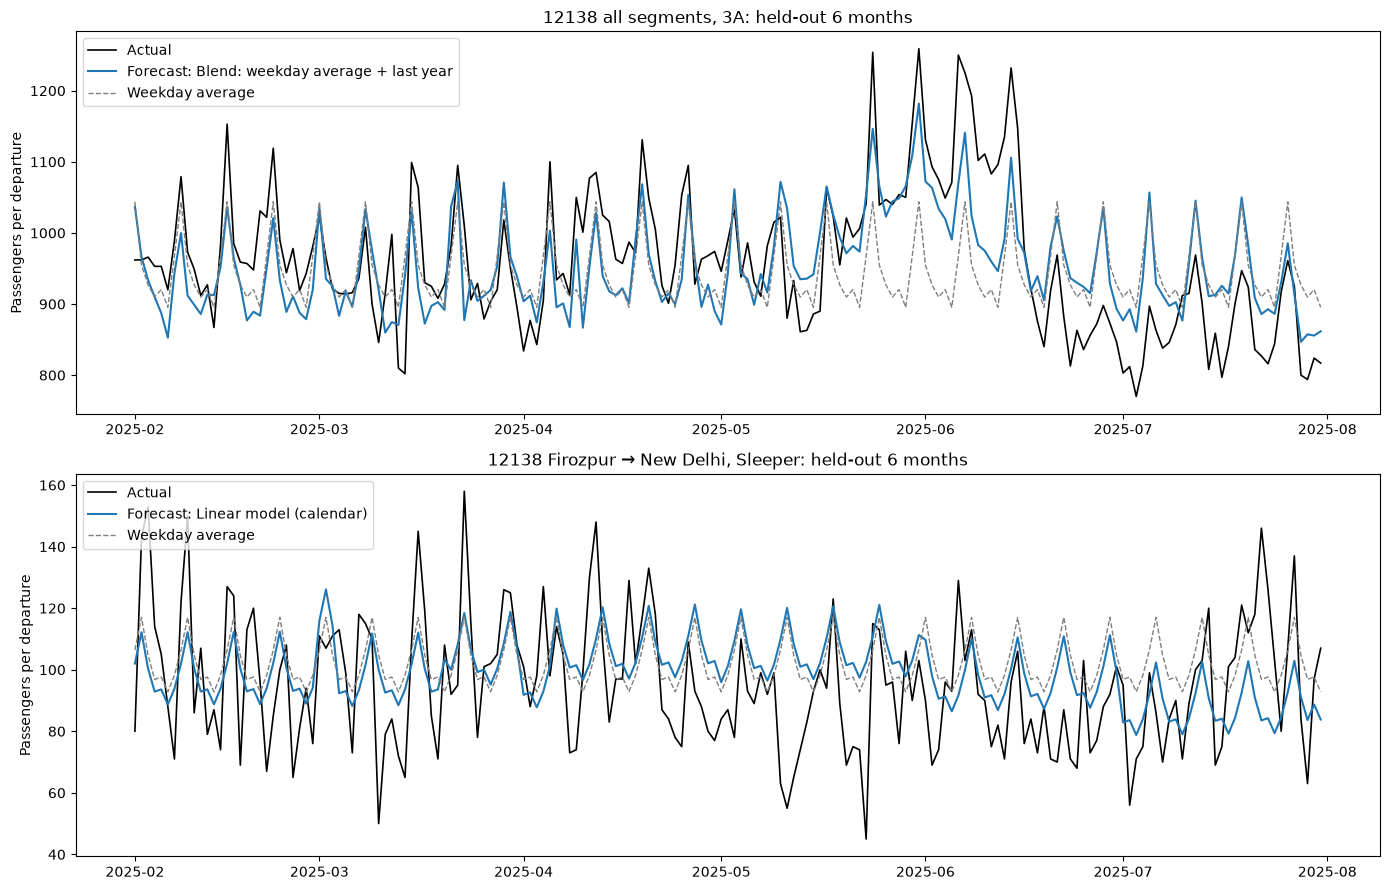

In [4]:
fig, axes = plt.subplots(len(results), 1, figsize=(14, 4.5 * len(results)))
for ax, (name, (table, test)) in zip(np.atleast_1d(axes), results.items()):
    best = table.drop("(Random 80/20 split, for comparison)")["MAE (passengers/day)"].idxmin()
    ax.plot(test.journey_date, test.total_psgn, color="black", lw=1.2, label="Actual")
    ax.plot(test.journey_date, test[best], color="tab:blue", lw=1.5, label=f"Forecast: {best}")
    ax.plot(test.journey_date, test["Baseline: weekday average"], color="tab:gray", ls="--", lw=1,
            label="Weekday average")
    ax.set_title(f"{name}: held-out 6 months")
    ax.set_ylabel("Passengers per departure")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## Updating the forecast as bookings arrive ("pickup")

Airlines don't stop forecasting when booking opens. Each day, the bookings already on hand say a lot about the final count: a departure that is filling fast is going to be busy. A **pickup forecast** combines the two pieces of information:

- **Additive pickup:** bookings so far, plus the extra bookings a departure on that weekday typically picks up from this point to departure (learned from the training months).
- **Combined:** a regression on bookings so far and the calendar blend from above.

Scored, as before, on Feb – Jul 2025, which the models never saw. This uses the booking-level records for train 12138, 3A.

,Booked so far (% of final),Calendar blend only,Additive pickup,Combined (pickup + calendar)
Days before departure,,,,
60,4.7,6.3,6.4,6.4
45,13.2,6.3,4.6,4.6
30,20.9,6.3,4.5,4.2
21,27.3,6.3,4.6,4.3
14,34.4,6.3,5.0,4.4
7,45.6,6.3,5.1,4.5
3,55.1,6.3,4.1,3.6
2,58.1,6.3,3.7,3.0
1,84.5,6.3,3.3,3.0


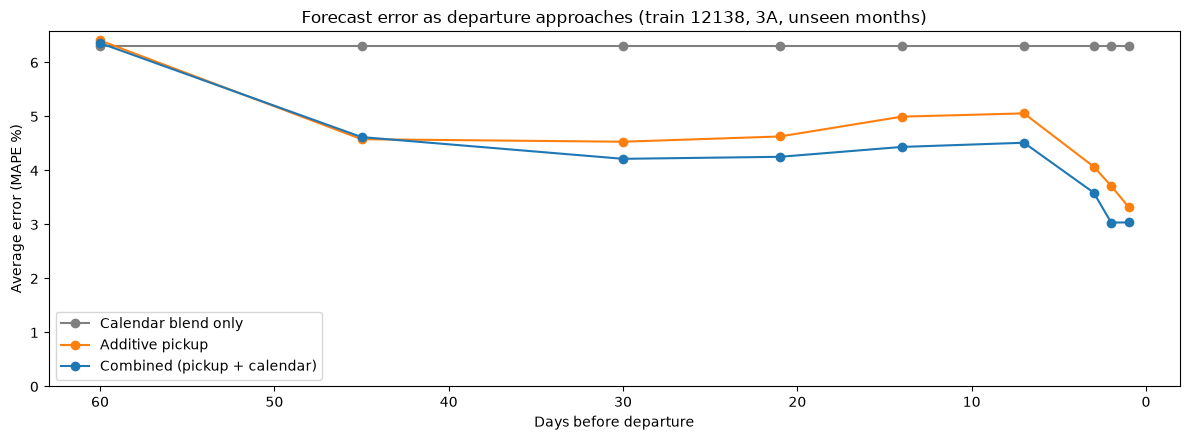

In [5]:
from sklearn.linear_model import LinearRegression

bookings = all_bookings[all_bookings.cls == "3A"].copy()
bookings["days_out"] = (bookings.journey_date - bookings.booking_date).dt.days.clip(lower=0)
by_day = bookings.pivot_table(index="journey_date", columns="days_out", values="PSGN", aggfunc="sum",
                              fill_value=0).reindex(columns=range(121), fill_value=0)
final = by_day.sum(axis=1)
booked_by = by_day.iloc[:, ::-1].cumsum(axis=1).iloc[:, ::-1]   # booked_by[d] = bookings made d or more days out

is_train = final.index < TEST_START
weekday = pd.Series(final.index.day_of_week, index=final.index)
calendar_blend = (0.5 * weekday.map(final[is_train].groupby(weekday[is_train]).mean())
                  + 0.5 * final.shift(364))


def mape(pred):
    actual = final[~is_train]
    return 100 * np.mean(np.abs(actual - pred[~is_train]) / actual)


rows = {}
for d in [60, 45, 30, 21, 14, 7, 3, 2, 1]:
    so_far = booked_by[d]
    typical_pickup = (final - so_far)[is_train].groupby(weekday[is_train]).mean()
    additive = so_far + weekday.map(typical_pickup)
    X = pd.DataFrame({"booked_so_far": so_far, "calendar_blend": calendar_blend})
    fit_rows = is_train & X.calendar_blend.notna()
    combined = pd.Series(LinearRegression().fit(X[fit_rows], final[fit_rows]).predict(X.fillna(X.mean())),
                         index=final.index)
    rows[d] = {"Booked so far (% of final)": 100 * (so_far / final)[~is_train].mean(),
               "Calendar blend only": mape(calendar_blend),
               "Additive pickup": mape(additive),
               "Combined (pickup + calendar)": mape(combined)}
pickup = pd.DataFrame(rows).T.rename_axis("Days before departure")
display(pickup.round(1))

ax = pickup[["Calendar blend only", "Additive pickup", "Combined (pickup + calendar)"]].plot(
    figsize=(12, 4.5), marker="o", color=["gray", "tab:orange", "tab:blue"])
ax.invert_xaxis()
ax.set(title="Forecast error as departure approaches (train 12138, 3A, unseen months)",
       xlabel="Days before departure", ylabel="Average error (MAPE %)")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

## Takeaways

- **Time-based testing matters.** A random split lets the model peek at neighbouring days and overstates accuracy. The held-out scores above are what to expect in practice.
- **For the whole train (3A), the best forecast is a simple blend.** Averaging "weekday average" and "same weekday last year" gives about 6% error on the unseen months, better than either rule alone and better than the ML models. It was picked on a separate validation window (Nov 2024 – Jan 2025) before looking at the test months.
- **The ML models don't beat simple rules yet.** With only two years of history, one of which is needed to build the "last year" feature, the models overfit. More history, or forecasting for many trains together, is the way to make them pay off.
- **A single segment in one class is too noisy to forecast well** (Firozpur → New Delhi, Sleeper: about 19% error at best). Pricing should be driven by train-level forecasts plus live booking pace.
- **Bookings on hand sharpen the forecast quickly.** Combining bookings so far with the calendar cuts the error from about 6% to about 4% a month before departure, and to about 3% the day before. This is the signal a pricing engine uses to react during the booking window.
- **These forecasts feed the pricing engine** ([`02_pricing_engine.ipynb`](02_pricing_engine.ipynb)). There, a forecast error of this size decides the starting fare, and the booking pace corrects it as the departure fills up.